Our Proposition is:

 Low-income countries are more affected by climate-related disasters than high-income countries 



In [46]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
# Climate change measured in CO2 emissisons 

climate_change_data = pd.read_csv("climate-change-raw-2021.csv", skiprows = 4)
climate_change_data = climate_change_data.drop(columns="Indicator Name")
climate_change_data = climate_change_data.drop(columns="Indicator Code")
climate_change_data.head()



,Country Name,Country Code,1960,1961,1962,1963,1964,1965,1966,1967,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,Unnamed: 65
0,Aruba,ABW,50.776,50.761000,50.746000,50.730000,50.715000,50.700000,50.685000,50.670000,...,42.957000,42.990000,43.041000,43.108000,43.192000,43.293000,43.411000,43.546000,43.697000,NaN
1,Aruba,ABW,27525.000,28139.000000,28537.000000,28763.000000,28922.000000,29080.000000,29246.000000,29411.000000,...,44059.000000,44351.000000,44666.000000,44978.000000,45293.000000,45614.000000,45949.000000,46294.000000,46654.000000,NaN
2,Aruba,ABW,NaN,2.206183,1.404498,0.788835,0.551271,0.544810,0.569216,0.562594,...,0.543931,0.660561,0.707733,0.696090,0.697901,0.706219,0.731740,0.748028,0.774631,NaN
3,Aruba,ABW,54208.000,55434.000000,56234.000000,56699.000000,57029.000000,57357.000000,57702.000000,58044.000000,...,102565.000000,103165.000000,103776.000000,104339.000000,104865.000000,105361.000000,105846.000000,106310.000000,106766.000000,NaN
4,Aruba,ABW,NaN,2.236462,1.432843,0.823502,0.580334,0.573498,0.599694,0.590951,...,0.503385,0.583290,0.590508,0.541048,0.502860,0.471874,0.459266,0.437415,0.428017,NaN


In [ ]:
# GDP measured in current international dollars (PPP) per capita.

gdp = pd.read_csv(
    "GDP-Per_capita-ppp.csv",
    skiprows=4
)
gdp = gdp.drop(columns=gdp.columns[gdp.columns.str.startswith("Unnamed")])
gdp = gdp.drop(columns = "Indicator Name")
gdp = gdp.drop(columns = "Indicator Code")
gdp.head()
gdp.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 68 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  266 non-null    object 
 1   Country Code  266 non-null    object 
 2   1960          0 non-null      float64
 3   1961          0 non-null      float64
 4   1962          0 non-null      float64
 5   1963          0 non-null      float64
 6   1964          0 non-null      float64
 7   1965          0 non-null      float64
 8   1966          0 non-null      float64
 9   1967          0 non-null      float64
 10  1968          0 non-null      float64
 11  1969          0 non-null      float64
 12  1970          0 non-null      float64
 13  1971          0 non-null      float64
 14  1972          0 non-null      float64
 15  1973          0 non-null      float64
 16  1974          0 non-null      float64
 17  1975          0 non-null      float64
 18  1976          0 non-null      

In [ ]:
# Droughts, Floods, extreme temperatures (% of population, avg 1990-2009)
extreme_temp_data = pd.read_csv("API_EN.CLC.MDAT.ZS_DS2_en_csv_v2_9888.csv", skiprows = 4)
extreme_temp_data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,"Droughts, floods, extreme temperatures (% of p...",EN.CLC.MDAT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
ext = pd.read_csv("API_EN.CLC.MDAT.ZS_DS2_en_csv_v2_9888.csv", skiprows=4)

year_cols = [c for c in ext.columns if c.isdigit()]

has_data = ext[year_cols].notna().sum()

print(has_data[has_data > 0])          


val_col = "2009"  

meta = pd.read_csv("Metadata_Country_API_EN.CLC.MDAT.ZS_DS2_en_csv_v2_9888.csv")

d = ext[["Country Name", "Country Code", val_col]].merge(

    meta[["Country Code", "IncomeGroup"]], on="Country Code")

d = d.rename(columns={val_col: "affected"})

d = d.dropna(subset=["affected", "IncomeGroup"])  


rder = ["Low income", "Lower middle income", "Upper middle income", "High income"]

print(d.groupby("IncomeGroup")["affected"].agg(["count", "mean", "median", "max"]).reindex(order))

2009    168
dtype: int64
                     count      mean    median       max
IncomeGroup                                             
Low income              24  2.299646  1.273005  8.820493
Lower middle income     44  1.838255  0.836957  9.226586
Upper middle income     51  0.920717  0.360637  7.950971
High income             49  0.275769  0.007102  7.170624


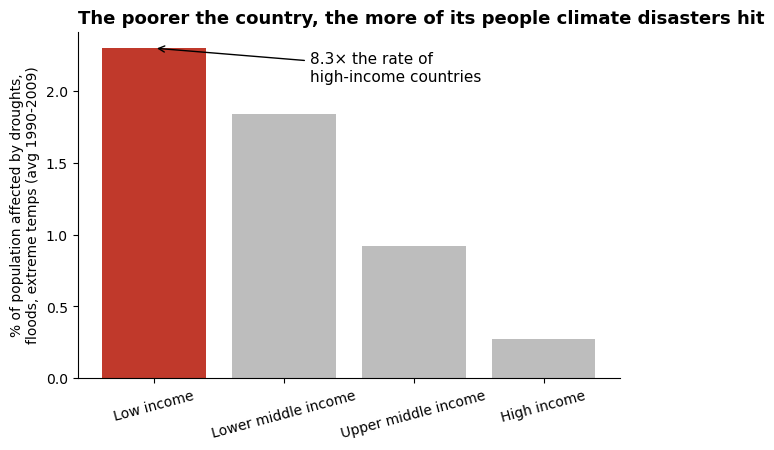

In [ ]:
g = d.groupby("IncomeGroup")["affected"].mean().reindex(order)

colors = ["#c0392b", "#bdbdbd", "#bdbdbd", "#bdbdbd"]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.bar(g.index, g.values, color=colors)

ax.set_title("The poorer the country, the more of its people climate disasters hit",loc="left", fontsize=13, weight="bold")

ax.set_ylabel("% of population affected by droughts,\nfloods, extreme temps (avg 1990-2009)")

ratio = g["Low income"] / g["High income"]

ax.annotate(f"{ratio:.1f}× the rate of\nhigh-income countries", xy=(0, g["Low income"]), xytext=(1.2, g["Low income"] * 0.9), arrowprops=dict(arrowstyle="->"), fontsize=11)

ax.spines[["top", "right"]].set_visible(False)

plt.xticks(rotation=15)

plt.show()

Decisison 1: using group mean instead of median for raw dist.
Score: -1.5
I used the mean because some very low income countrires inflate that value. making the gap look larger then it actually is. We thought about using the mean makes the gaps less wide so 

Decision 2: Make the low income bar red and everything else gray.
Score: 1
The color makes the bar a lot more noticeable, emphasizing the effect presented. But this decision didnt change any values so we think its not that deceitful.  I considered choosing a different color, like blue, but that didn't pop out as much as the red. 

Decision 3: "8.3x the rate of high income countries"
Score: 0.5
- This number was not enlarged or exagerated in any way, so we think it's okay. I considered not having this as part of the chart but i think it feels more impactful with it there. 

                       median  share_over1
IncomeGroup                               
Low income           1.273005    58.333333
Lower middle income  0.836957    43.181818
Upper middle income  0.360637    27.450980
High income          0.007102     4.081633


/var/folders/x9/w922977x70dgb30kh3qvmw4m0000gn/T/ipykernel_79608/1326810988.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=d, x="IncomeGroup", y="affected", order=order,
/var/folders/x9/w922977x70dgb30kh3qvmw4m0000gn/T/ipykernel_79608/1326810988.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels)


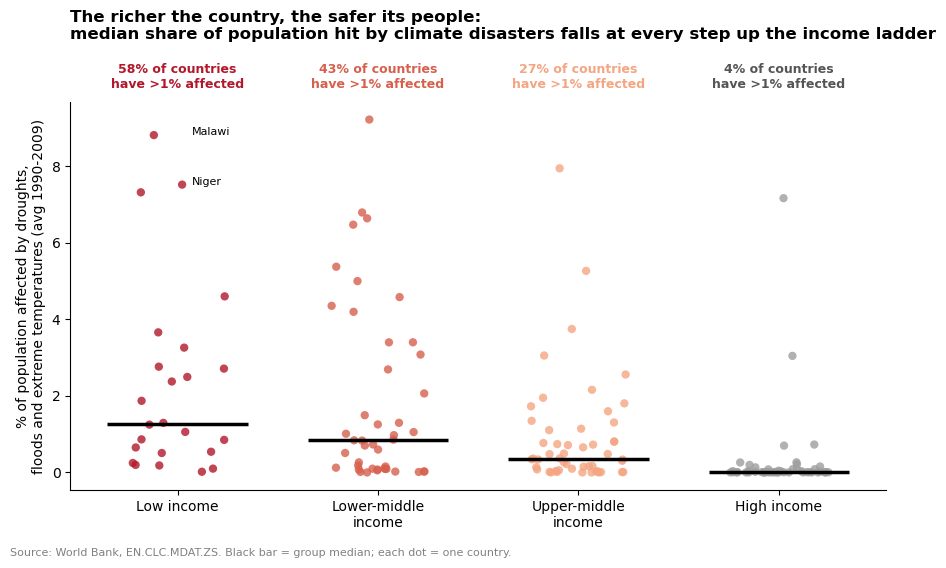

In [ ]:
order = ["Low income", "Lower middle income", "Upper middle income", "High income"]
labels = ["Low income", "Lower-middle\nincome", "Upper-middle\nincome", "High income"]
palette = ["#b2182b", "#d6604d", "#f4a582", "#9e9e9e"]   

stats = d.groupby("IncomeGroup")["affected"].agg(
    median="median",
    share_over1=lambda s: (s > 1).mean() * 100,
).reindex(order)
print(stats)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.stripplot(data=d, x="IncomeGroup", y="affected", order=order,
              palette=palette, size=6, alpha=0.8, jitter=0.25, ax=ax)

for i, grp in enumerate(order):
    m = stats.loc[grp, "median"]
    ax.hlines(m, i - 0.35, i + 0.35, color="black", lw=2.5, zorder=3)

for i, grp in enumerate(order):
    ax.text(i, d["affected"].max() * 1.08,
            f"{stats.loc[grp, 'share_over1']:.0f}% of countries\nhave >1% affected",
            ha="center", va="bottom", fontsize=9, color=palette[i] if i < 3 else "#555",
            weight="bold")

for _, r in d[d.IncomeGroup == "Low income"].nlargest(2, "affected").iterrows():
    ax.annotate(r["Country Name"], (0, r["affected"]),
                xytext=(10, 0), textcoords="offset points", fontsize=8)

ax.set_xticklabels(labels)
ax.set_xlabel("")
ax.set_ylabel("% of population affected by droughts,\nfloods and extreme temperatures (avg 1990-2009)")
ax.set_title("The richer the country, the safer its people:\n"
             "median share of population hit by climate disasters falls at every step up the income ladder",
             loc="left", fontsize=12, weight="bold", pad=45)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, -0.02, "Source: World Bank, EN.CLC.MDAT.ZS. Black bar = group median; each dot = one country.",
         fontsize=8, color="gray")
plt.tight_layout()
plt.show()

Decision 1: Show every country as a dot, with the group median as a black bar

Score: 1.5
Plotting all countries keeps the data transparent. we considered a bar chart o but the strip plot looks more credible and was easier to see

Decision 2: Add a “% of countries with >1% affected” annotation above each group

Score: -1
This turns the dot cloud into one number per group (58%, 43%, 27%, 4%), and the steady drop is the strongest evidence for the claim. The numbers are computed from the data, so they’re accurate. But I picked the 1% threshold because it produces a better gradient.

Decision 3: Using a color scale from red to gray

Score: -0.5
The colors fading makes the effect feel more harmful and makes the higher income label feel "safer". No values were changed for this. we thought of using more blueish colors but that didnt feel as impactful. 